In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error
import datetime as datetime

In [ ]:
folder_with_data = '../Data/Final-Data'

river_flow = pd.read_csv(folder_with_data + '/river-flow.csv')
river_flow['dateTime'] = pd.to_datetime(river_flow['dateTime'], errors='raise').dt.date
river_flow = river_flow.groupby('dateTime').mean().reset_index()

climate_variables = pd.read_csv(folder_with_data + '/atmospheric-variables.csv')
climate_variables['dateTime'] = pd.to_datetime(
    climate_variables['dateTime'],
    errors='raise'
)

numeric_cols = climate_variables.select_dtypes(include=np.number).columns
climate_variables[numeric_cols] = climate_variables[numeric_cols].interpolate(
    method='linear',
    limit_direction='both'
)

climate_variables['dateTime'] = climate_variables['dateTime'].dt.date

river_flow = river_flow.drop(columns='Unnamed: 0')

weather_data = pd.merge(
    climate_variables,
    river_flow,
    on='dateTime',
    how='inner'
)

weather_data = weather_data.iloc[:, [0,3,1,4,5,6,7,8,9,10,11,12,13]]

time_steps = 30
horizon = 7

numerical_columns = weather_data.select_dtypes(include=np.number).columns

In [ ]:
actuals_mul = np.load('actuals-mul.npy')

In [4]:
def ensemble_predict(predictions): 
    predictions = np.array(predictions)
    avg_predictions = np.mean(predictions, axis=0)  
    return avg_predictions

def confidence_bands(predictions):
    predictions = np.array(predictions)
    mean = np.mean(predictions, axis=0)

    std = np.std(predictions, axis=0, ddof=1)

    n = predictions.shape[0]

    z = 1.96  # 95% confidence

    margin = z * std / np.sqrt(n)

    lower = mean - margin
    upper = mean + margin

    return lower, upper

def rob_prediction_intervals(predictions, actuals, confidence=0.95):
    """
    Calculates heteroscedastic prediction intervals using a log-space transform. This naturally pinches intervals at base flows
    and widens them at peaks.
    """
    predictions = np.array(predictions)
    actuals = np.array(actuals)
    n_runs = predictions.shape[0]
        
    log_predictions = np.log(predictions + 1.0)
    log_actuals = np.log(actuals + 1.0)
    
    log_ensemble_mean = np.mean(log_predictions, axis=0)
    log_ensemble_var = np.var(log_predictions, axis=0, ddof=1)
    
    log_residuals = log_actuals - log_ensemble_mean
    log_residual_var = np.var(log_residuals, axis=0, ddof=1, keepdims=True)
    log_total_std = np.sqrt(log_ensemble_var * (1 + 1/n_runs) + log_residual_var)
    
    z_map = {0.90: 1.645, 0.95: 1.96, 0.99: 2.576}
    z = z_map.get(confidence, 1.96)
    
    log_lower = log_ensemble_mean - (z * log_total_std)
    log_upper = log_ensemble_mean + (z * log_total_std)
    
    lower = np.exp(log_lower) - 1.0
    upper = np.exp(log_upper) - 1.0
    lower = np.clip(lower, a_min=0, a_max=None)
    
    return lower, upper

In [5]:
data = np.load("final-predictions-4-all-mul.npz")

predictions_lstm1_mul = data["predictions_lstm1_mul"]
predictions_lstm_dyn1_mul = data["predictions_lstm_dyn1_mul"]

predictions_encdec1_mul = data["predictions_encdec1_mul"]
predictions_encdec_dyn1_mul = data["predictions_encdec_dyn1_mul"]

lower_bands_encdec1_mul = data["lower_bands_encdec1_mul"]
lower_bands_encdec_dyn1_mul = data["lower_bands_encdec_dyn1_mul"]
upper_bands_encdec1_mul = data["upper_bands_encdec1_mul"]
upper_bands_encdec_dyn1_mul = data["upper_bands_encdec_dyn1_mul"]

pr_lower_bands_encdec1_mul = data["pr_lower_bands_encdec1_mul"]
pr_lower_bands_encdec_dyn1_mul = data["pr_lower_bands_encdec_dyn1_mul"]
pr_upper_bands_encdec1_mul = data["pr_upper_bands_encdec1_mul"]
pr_upper_bands_encdec_dyn1_mul = data["pr_upper_bands_encdec_dyn1_mul"]

predictions_rf1 = data["predictions_rf1"]
lower_bands_rf1 = data["lower_bands_rf1"]
upper_bands_rf1 = data["upper_bands_rf1"]
pr_lower_bands_rf1 = data["pr_lower_bands_rf1"]
pr_upper_bands_rf1 = data["pr_upper_bands_rf1"]

predictions_svr1 = data["predictions_svr1"]
lower_bands_svr1 = data["lower_bands_svr1"]
upper_bands_svr1 = data["upper_bands_svr1"]
pr_lower_bands_svr1 = data["pr_lower_bands_svr1"]
pr_upper_bands_svr1 = data["pr_upper_bands_svr1"]

predictions_1dcnn1_mul = data["predictions_1dcnn1_mul"]
lower_bands_1dcnn1_mul = data["lower_bands_1dcnn1_mul"]
upper_bands_1dcnn1_mul = data["upper_bands_1dcnn1_mul"]
pr_lower_bands_1dcnn1_mul = data["pr_lower_bands_1dcnn1_mul"]
pr_upper_bands_1dcnn1_mul = data["pr_upper_bands_1dcnn1_mul"]

In [6]:
def calculate_mase(actual, predicted, m, eps=1e-8):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    naive_error = np.abs(actual[m:] - actual[:-m])
    forecast_error = np.abs(actual[m:] - predicted[m:])

    denom = np.mean(naive_error)

    if denom < eps:
        return np.nan

    return np.mean(forecast_error) / denom

def nash_sutcliffe_efficiency(observed, predicted):
    observed = np.array(observed)
    predicted = np.array(predicted)

    numerator = np.sum((observed - predicted) ** 2)
    denominator = np.sum((observed - np.mean(observed)) ** 2)

    return 1 - (numerator / denominator)

In [7]:
n_stations = 6
error_metrics = []

# model_registry = {
#     "RF": {
#         "preds": predictions_rf1,
#         "lower": pr_lower_bands_rf1,
#         "upper": pr_upper_bands_rf1
#     },
#     "SVR": {
#         "preds": predictions_svr1,
#         "lower": pr_lower_bands_svr1,
#         "upper": pr_upper_bands_svr1
#     },
#     "1DCNN":{
#         "preds": predictions_1dcnn1_mul,
#         "lower": pr_lower_bands_1dcnn1_mul,
#         "upper": pr_upper_bands_1dcnn1_mul
#     }
#     ,
#     "LSTM-EncDec-DFF": {
#         "preds": predictions_encdec1_mul,
#         "lower": pr_lower_bands_encdec1_mul,
#         "upper": pr_upper_bands_encdec1_mul
#     }
#     ,
#     "LSTM-EncDec-DFF-2": {
#         "preds": predictions_encdec_dyn1_mul,
#         "lower": pr_lower_bands_encdec_dyn1_mul,
#         "upper": pr_upper_bands_encdec_dyn1_mul
#     }
# }

# for model_name, arrays in model_registry.items():
    
#     model_predictions = arrays["preds"].reshape(-1, n_stations).flatten()
#     lower_bounds = arrays["lower"].reshape(-1, n_stations).flatten()
#     upper_bounds = arrays["upper"].reshape(-1, n_stations).flatten()
    
#     actuals_flat = actuals_mul.flatten()

#     df = pd.DataFrame({'timestamp': range(0, len(actuals_flat)), 'Flow': actuals_flat})
    
#     df2 = pd.DataFrame({
#         'timestamp': range(0, len(model_predictions)),
#         'Flow': model_predictions,
#         'Lower_Band': lower_bounds,
#         'Upper_Band': upper_bounds
#     })

#     threshold_high = df['Flow'].quantile(0.95)  
#     threshold_low = df['Flow'].quantile(0.05)   

#     extreme_highs = df[df['Flow'] >= threshold_high]
#     extreme_highs2 = df2[df['Flow'] >= threshold_high] 

#     mae = round(mean_absolute_error(df['Flow'], df2['Flow']), 2)
#     nse = round(nash_sutcliffe_efficiency(df['Flow'], df2['Flow']), 2)
#     mase = round(calculate_mase(df['Flow'], df2['Flow'], 20), 2)
#     mae_high = round(mean_absolute_error(extreme_highs['Flow'], extreme_highs2['Flow']), 2)
    
#     inside_interval = (df['Flow'] >= df2['Lower_Band']) & (df['Flow'] <= df2['Upper_Band'])
#     picp = round(np.mean(inside_interval), 3)


#     mpiw = round(np.mean(df2['Upper_Band'] - df2['Lower_Band']), 3)

#     error_metrics_df = pd.DataFrame({
#         'Model': [model_name],
#         'MAE': [mae],
#         'NSE': [nse],
#         'MASE': [mase],
#         'MAE_HIGH': [mae_high],
#         'PICP (Coverage)': [picp], 
#         'MPIW (Width)': [mpiw]    
#     })

#     error_metrics.append(error_metrics_df)
  
# error_metrics = pd.concat(error_metrics, axis=0).reset_index(drop=True)
# print(error_metrics)

model_registry = {
    "RF": {
        "preds": predictions_rf1,
        "lower": lower_bands_rf1,
        "upper": upper_bands_rf1
    },
    "SVR": {
        "preds": predictions_svr1,
        "lower": lower_bands_svr1,
        "upper": upper_bands_svr1
    },
    "1DCNN":{
        "preds": predictions_1dcnn1_mul,
        "lower": lower_bands_1dcnn1_mul,
        "upper": upper_bands_1dcnn1_mul
    }
    ,
    "LSTM-EncDec-DFF": {
        "preds": predictions_encdec1_mul,
        "lower": lower_bands_encdec1_mul,
        "upper": upper_bands_encdec1_mul
    }
    ,
    "LSTM-EncDec-DFF-2": {
        "preds": predictions_encdec_dyn1_mul,
        "lower": lower_bands_encdec_dyn1_mul,
        "upper": upper_bands_encdec_dyn1_mul
    }
}

def format_metric_with_bands(base_val, lower_val, upper_val):
    """Calculates the margin and formats as 'Base ± Margin'"""
    margin_lower = abs(base_val - lower_val)
    margin_upper = abs(upper_val - base_val)
    avg_margin = (margin_lower + margin_upper) / 2
    
    return f"{round(base_val, 2)} ± {round(avg_margin, 2)}"

for model_name, arrays in model_registry.items():
    
    preds_flat = arrays["preds"].reshape(-1, n_stations).flatten()
    lower_flat = arrays["lower"].reshape(-1, n_stations).flatten()
    upper_flat = arrays["upper"].reshape(-1, n_stations).flatten()
    actuals_flat = actuals_mul.flatten()

    df_actual = pd.DataFrame({'Flow': actuals_flat})
    threshold_high = df_actual['Flow'].quantile(0.95)  
    extreme_highs_actual = df_actual[df_actual['Flow'] >= threshold_high]

    results = {}
    variants = {'base': preds_flat, 'lower': lower_flat, 'upper': upper_flat}

    for v_name, v_data in variants.items():
        df_variant = pd.DataFrame({'Flow': v_data})
        extreme_highs_variant = df_variant[df_actual['Flow'] >= threshold_high]

        results[v_name] = {
            'mae': mean_absolute_error(df_actual['Flow'], df_variant['Flow']),
            'nse': nash_sutcliffe_efficiency(df_actual['Flow'], df_variant['Flow']),
            'mase': calculate_mase(df_actual['Flow'], df_variant['Flow'], 20),
            'mae_high': mean_absolute_error(extreme_highs_actual['Flow'], extreme_highs_variant['Flow'])
        }

    model_metrics_df = pd.DataFrame({
        'Model': [model_name],
        'MAE': [format_metric_with_bands(results['base']['mae'], results['lower']['mae'], results['upper']['mae'])],
        'NSE': [format_metric_with_bands(results['base']['nse'], results['lower']['nse'], results['upper']['nse'])],
        'MASE': [format_metric_with_bands(results['base']['mase'], results['lower']['mase'], results['upper']['mase'])],
        'MAE_HIGH': [format_metric_with_bands(results['base']['mae_high'], results['lower']['mae_high'], results['upper']['mae_high'])]
    })

    error_metrics.append(model_metrics_df)
  
error_metrics = pd.concat(error_metrics, axis=0).reset_index(drop=True)
print(error_metrics)

               Model           MAE          NSE         MASE       MAE_HIGH
0                 RF  28.04 ± 0.21   0.73 ± 0.0   0.53 ± 0.0  126.92 ± 3.77
1                SVR  29.56 ± 2.38   0.7 ± 0.02  0.56 ± 0.05  116.16 ± 9.09
2              1DCNN   28.6 ± 1.22   0.74 ± 0.0  0.55 ± 0.02  116.52 ± 7.48
3    LSTM-EncDec-DFF   27.6 ± 0.48   0.75 ± 0.0  0.53 ± 0.01  112.82 ± 6.58
4  LSTM-EncDec-DFF-2  25.97 ± 0.78  0.76 ± 0.01   0.5 ± 0.01  108.88 ± 7.91


In [8]:
n_leads = 7
n_total = actuals_mul.shape[0]

n_samples = n_total // n_leads
actual_reshaped = actuals_mul.reshape(n_samples, n_leads, n_stations)

preds_dict = {}

for name, model in zip(
    ["LSTM-EncDec-DFF", "LSTM-EncDec-DFF-2"],
    [predictions_encdec1_mul, predictions_encdec_dyn1_mul]
):
    preds_dict[name] = model.reshape(n_samples, n_leads, n_stations)

In [ ]:
predictions_per_model_un = np.load("predictions-per-model-un.npy")
upper_predictions_per_model_un = np.load('prl-upper_predictions-per-model-un.npy')
lower_predictions_per_model_un = np.load('prl-lower_predictions-per-model-un.npy')
upperb_predictions_per_model_un = np.load('upper_predictions-per_model-un.npy')
lowerb_predictions_per_model_un = np.load('lower_predictions-per-model-un.npy')

In [10]:
# performance across all leads
lead_metrics = []

for model_name, preds in preds_dict.items():

    for lead in range(n_leads):

        y_true = actual_reshaped[:, lead, :].flatten()
        y_pred = preds[:, lead, :].flatten()

        mae = mean_absolute_error(y_true, y_pred)
        nse = nash_sutcliffe_efficiency(y_true, y_pred)
        mase = calculate_mase(y_true, y_pred, 20)

        peak_mask = y_true >= np.percentile(y_true, 95)
        mae_high = mean_absolute_error(y_true[peak_mask], y_pred[peak_mask])

        lead_metrics.append({
            "Model": model_name,
            "Lead": lead + 1,
            "MAE": mae,
            "NSE": nse,
            "MASE": mase,
            "MAE_HIGH": mae_high
        })

lead_df = pd.DataFrame(lead_metrics)
lead_df

,Model,Lead,MAE,NSE,MASE,MAE_HIGH
0,LSTM-EncDec-DFF,1,17.410574,0.898499,0.323207,81.207989
1,LSTM-EncDec-DFF,2,19.341821,0.874648,0.359070,85.399999
2,LSTM-EncDec-DFF,3,23.531430,0.819521,0.436706,96.194570
3,LSTM-EncDec-DFF,4,27.772458,0.752711,0.515197,110.300755
4,LSTM-EncDec-DFF,5,31.797854,0.687031,0.589544,126.153052
5,LSTM-EncDec-DFF,6,35.268007,0.626187,0.653671,140.152862
6,LSTM-EncDec-DFF,7,38.093632,0.572064,0.705931,150.315998
7,LSTM-EncDec-DFF-2,1,14.880798,0.933275,0.276221,49.491981
8,LSTM-EncDec-DFF-2,2,17.517316,0.897604,0.325189,64.586463
9,LSTM-EncDec-DFF-2,3,22.331398,0.832471,0.414409,88.032381


In [11]:
error_metrics = []

models = [
    "RF",
    "SVR",
    "1DCNN",
    "LSTM-EncDec-DFF",
    "LSTM-EncDec-DFF-2"
]

for model_name, model in zip(models,[predictions_rf1,predictions_svr1,predictions_1dcnn1_mul,predictions_encdec1_mul,predictions_encdec_dyn1_mul,predictions_lstm1_mul,predictions_lstm_dyn1_mul]):
    
  extreme_highs_per_station = []
  extreme_highs2_per_station= []
  mae_high_per_station = []
  mae_low_per_station = []
  mae_per_station = []
  nse_per_station = []
  mase_per_station = []
  
  model_predictions =  model.reshape(-1,n_stations)

  for i,name in zip(range(n_stations), weather_data.columns[7:]):

      df = pd.DataFrame({'timestamp': range(0,len(actuals_mul[:,i]+1)),'Flow': actuals_mul[:,i]})

      threshold_high = df['Flow'].quantile(0.95)  

      extreme_highs = df[df['Flow'] >= threshold_high]

      df2 = pd.DataFrame({'timestamp': range(0,len(actuals_mul[:,i]+1)),'Flow': model_predictions[:,i]})

      threshold_high2 = df['Flow'].quantile(0.95)  
      threshold_low2 = df['Flow'].quantile(0.05)   

      extreme_highs2 = df2[df['Flow'] >= threshold_high2]
      extreme_lows2 = df2[df['Flow'] <= threshold_low2]

      num_extremes = min(len(extreme_highs), len(extreme_highs2))

      extreme_highs = extreme_highs.nlargest(num_extremes, 'Flow').reset_index(drop=True)
      extreme_highs2 = extreme_highs2.nlargest(num_extremes, 'Flow').reset_index(drop=True)

      extreme_highs_per_station.append(extreme_highs)
      extreme_highs2_per_station.append(extreme_highs2)

      mae_high = round(mean_absolute_error(extreme_highs['Flow'], extreme_highs2['Flow']),2)
      mae_high_per_station.append(mae_high)
      mae = round(mean_absolute_error(np.array(df['Flow']), np.array(df2['Flow'])),2)
      mae_per_station.append(mae)

      nse = round(nash_sutcliffe_efficiency(np.array(df['Flow']), np.array(df2['Flow'])),2)
      nse_per_station.append(nse)
      mase = round(calculate_mase(np.array(df['Flow']), np.array(df2['Flow']),20),2)
      mase_per_station.append(mase)

  error_metrics_df = pd.DataFrame({
      'Model' : model_name,
      'Station': [f'{name}' for name in weather_data.columns[7:]],
      'MAE': mae_per_station,
      'NSE' : nse_per_station,
      'MASE': mase_per_station,
      'MAE_HIGH': mae_high_per_station
  })

  error_metrics.append(error_metrics_df)

error_metrics = pd.concat(error_metrics,axis=0).reset_index()
print(error_metrics)

    index              Model Station    MAE   NSE  MASE  MAE_HIGH
0       0                 RF   54001  23.22  0.70  1.08    107.15
1       1                 RF   54005  19.56  0.64  1.21     66.20
2       2                 RF   54032  33.24  0.76  1.16    120.27
3       3                 RF   54057  39.06  0.75  1.14    155.32
4       4                 RF   54095  25.88  0.64  1.08    133.66
5       5                 RF   55002  27.27  0.46  1.08    148.60
6       0                SVR   54001  24.81  0.66  1.16     97.45
7       1                SVR   54005  20.97  0.55  1.29     67.70
8       2                SVR   54032  33.09  0.75  1.15     92.05
9       3                SVR   54057  41.64  0.72  1.21    111.75
10      4                SVR   54095  28.45  0.59  1.19    128.08
11      5                SVR   55002  28.41  0.40  1.13    151.27
12      0              1DCNN   54001  23.80  0.71  1.11     97.28
13      1              1DCNN   54005  19.83  0.65  1.22     59.68
14      2 

In [12]:
station_names = ['54001', '54005', '54032', '54057', '54095', '55002']

station_lead_metrics = []

for model_name, preds in preds_dict.items():

    for s_idx, station in enumerate(station_names):

        for lead in range(n_leads):

            y_true = actual_reshaped[:, lead, s_idx]
            y_pred = preds[:, lead, s_idx]

            mae = mean_absolute_error(y_true, y_pred)
            nse = nash_sutcliffe_efficiency(y_true, y_pred)

            peak_mask = y_true >= np.percentile(y_true, 95)
            mae_high = mean_absolute_error(y_true[peak_mask], y_pred[peak_mask])

            station_lead_metrics.append({
                "Model": model_name,
                "Station": station,
                "Horizon step": lead + 1,
                "MAE": mae,
                "NSE": nse,
                "MAE_HIGH": mae_high
            })

station_lead_df = pd.DataFrame(station_lead_metrics)
station_lead_df

,Model,Station,Horizon step,MAE,NSE,MAE_HIGH
0,LSTM-EncDec-DFF,54001,1,14.374698,0.882674,78.624974
1,LSTM-EncDec-DFF,54001,2,15.359546,0.868143,79.727589
2,LSTM-EncDec-DFF,54001,3,19.324174,0.800545,87.962286
3,LSTM-EncDec-DFF,54001,4,23.309991,0.714038,101.646888
4,LSTM-EncDec-DFF,54001,5,27.107548,0.630381,115.406976
...,...,...,...,...,...,...
79,LSTM-EncDec-DFF-2,55002,3,24.401942,0.531975,132.849893
80,LSTM-EncDec-DFF-2,55002,4,26.723369,0.458271,145.140338
81,LSTM-EncDec-DFF-2,55002,5,28.453312,0.404265,153.194751
82,LSTM-EncDec-DFF-2,55002,6,29.878021,0.366022,159.355331


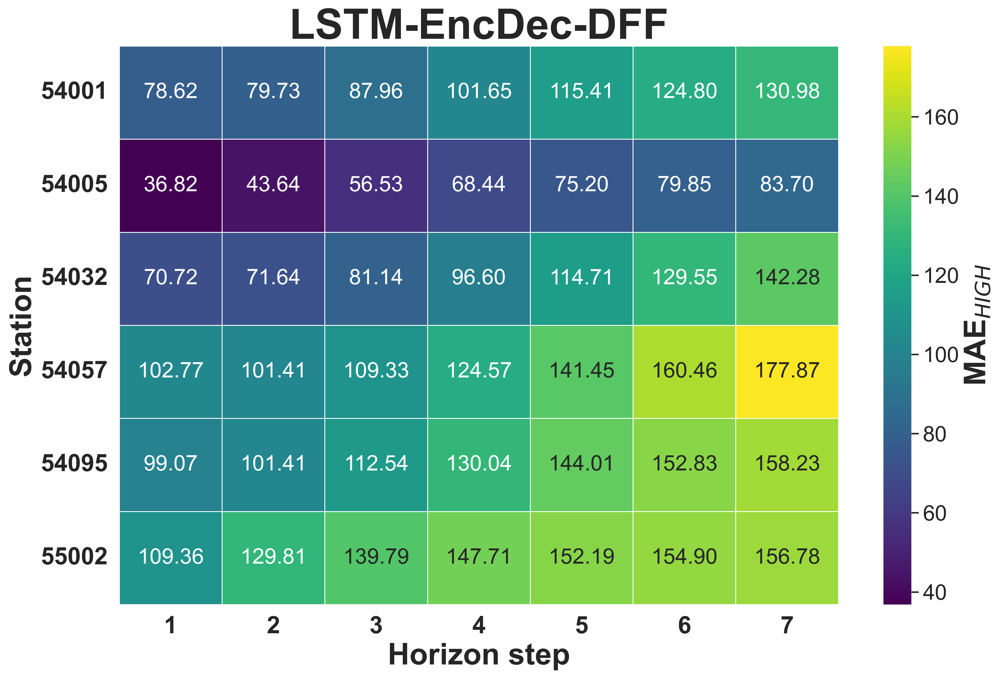

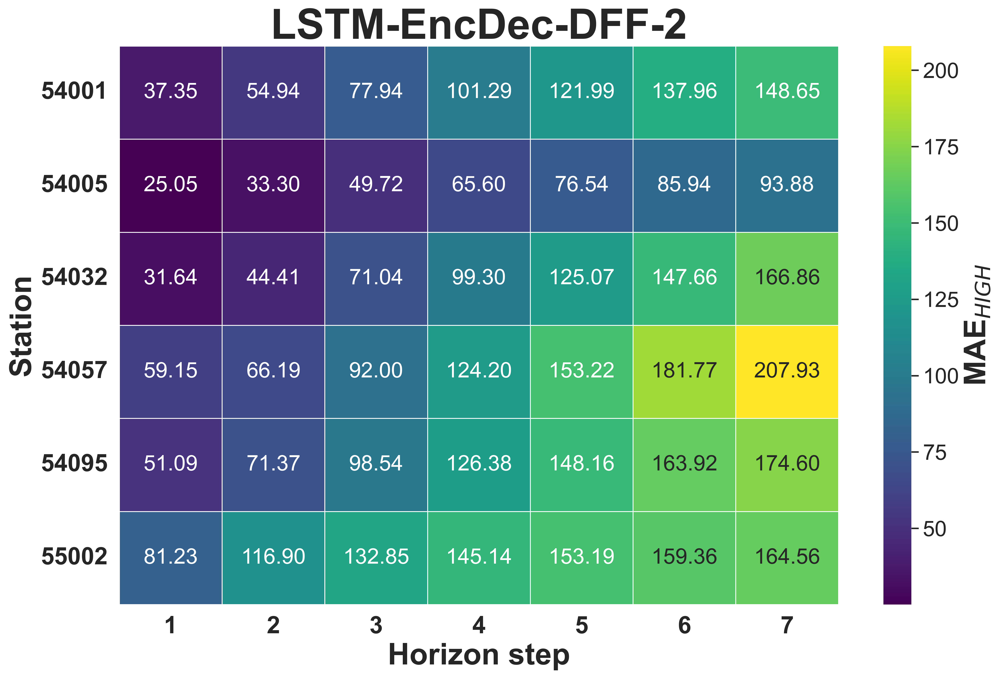

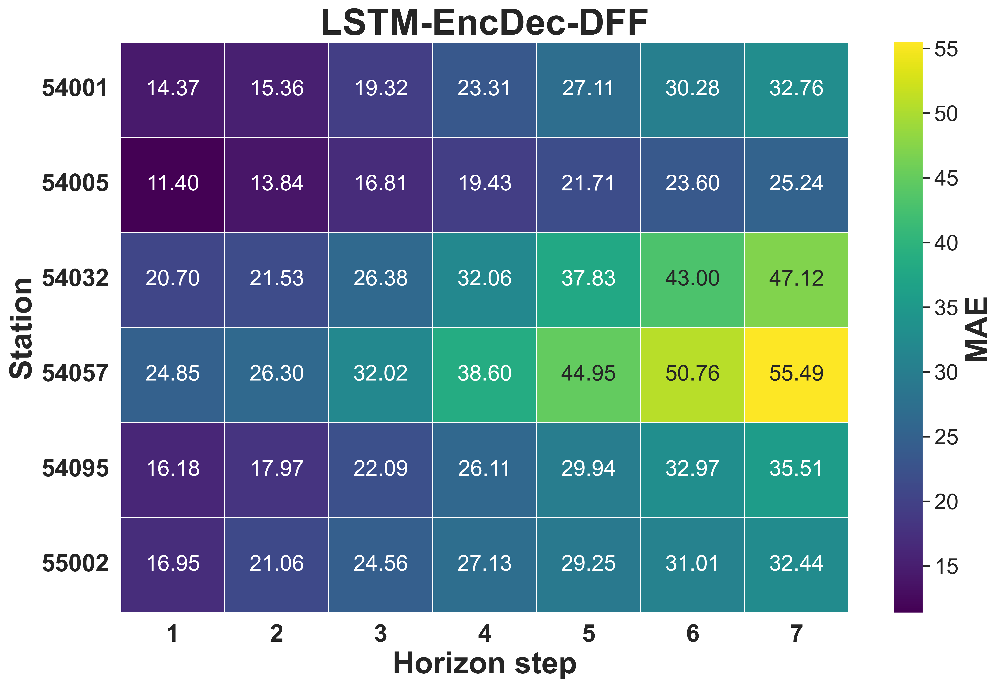

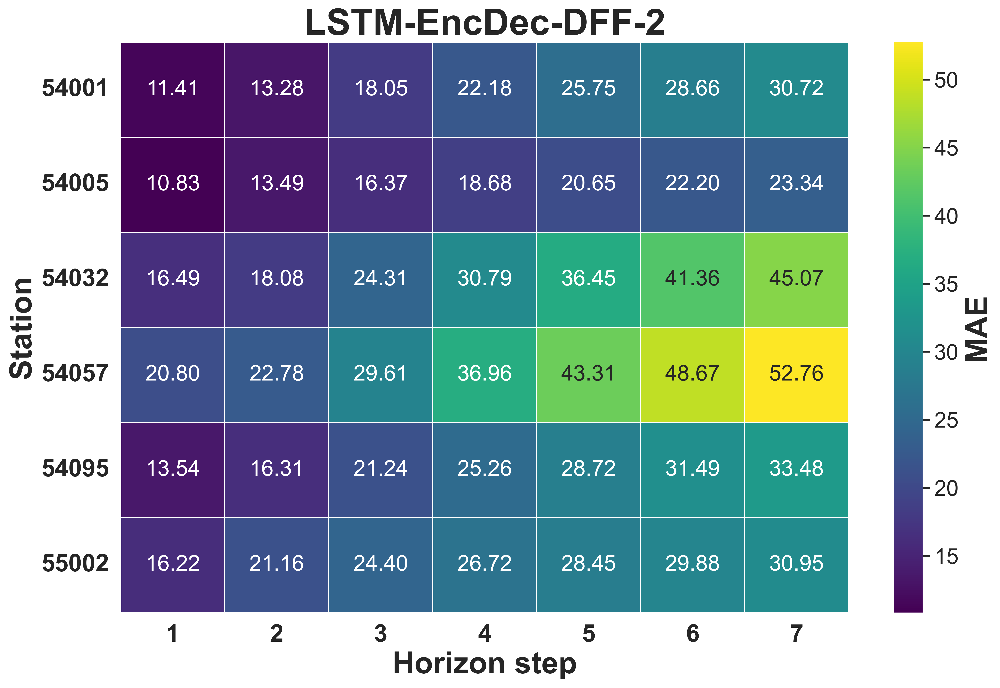

In [13]:
sns.set_theme(style="white")

for model_name in station_lead_df["Model"].unique():

    subset = station_lead_df[station_lead_df["Model"] == model_name]

    pivot = subset.pivot(index="Station", columns="Horizon step", values="MAE_HIGH")

    fig, ax = plt.subplots(figsize=(12, 8), dpi=500)

    hm = sns.heatmap(
        pivot,
        cmap="viridis",
        annot=True,
        fmt=".2f",
        linewidths=0.5,
        annot_kws={"size": 18},
        cbar_kws={"label": r"MAE$_{HIGH}$"},
        ax=ax
    )

    cbar = hm.collections[0].colorbar
    cbar.set_label(r"MAE$_{HIGH}$", fontsize=25, fontweight="bold")
    cbar.ax.tick_params(labelsize=18)

    ax.set_title(f"{model_name}", fontsize=35, fontweight="bold")
    ax.set_xlabel("Horizon step", fontsize=25, fontweight="bold")
    ax.set_ylabel("Station", fontsize=25, fontweight="bold")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=20, fontweight="bold")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=20, fontweight="bold")

    plt.tight_layout()
    plt.show()

for model_name in station_lead_df["Model"].unique():

    subset = station_lead_df[station_lead_df["Model"] == model_name]

    pivot = subset.pivot(index="Station", columns="Horizon step", values="MAE")

    fig, ax = plt.subplots(figsize=(12, 8), dpi=500)

    hm = sns.heatmap(
        pivot,
        cmap="viridis",
        annot=True,
        fmt=".2f",
        linewidths=0.5,
        annot_kws={"size": 18},
        cbar_kws={"label": r"MAE"},
        ax=ax
    )

    cbar = hm.collections[0].colorbar
    cbar.set_label(r"MAE", fontsize=25, fontweight="bold")
    cbar.ax.tick_params(labelsize=18)

    ax.set_title(f"{model_name}", fontsize=30, fontweight="bold")
    ax.set_xlabel("Horizon step", fontsize=25, fontweight="bold")
    ax.set_ylabel("Station", fontsize=25, fontweight="bold")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=20, fontweight="bold")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=20, fontweight="bold")

    plt.tight_layout()
    plt.show()

In [14]:
n_total = actuals_mul.shape[0]

n_samples = n_total // n_leads
actual_reshaped = actuals_mul.reshape(n_samples, n_leads, n_stations)

preds_dict = {}

for name, model in zip(
    ["RF","SVR", "1DCNN","LSTM-EncDec-DFF", "LSTM-EncDec-DFF-2"],
    [predictions_rf1, predictions_svr1, predictions_1dcnn1_mul, predictions_encdec1_mul, predictions_encdec_dyn1_mul]
):
    preds_dict[name] = model.reshape(n_samples, n_leads, n_stations)

In [15]:
station_names = ['54001', '54005', '54032', '54057', '54095', '55002']

station_lead_metrics = []

for model_name, preds in preds_dict.items():

    for s_idx, station in enumerate(station_names):

        for lead in range(n_leads):

            y_true = actual_reshaped[:, lead, s_idx]
            y_pred = preds[:, lead, s_idx]

            mae = mean_absolute_error(y_true, y_pred)
            nse = nash_sutcliffe_efficiency(y_true, y_pred)

            peak_mask = y_true >= np.percentile(y_true, 95)
            mae_high = mean_absolute_error(y_true[peak_mask], y_pred[peak_mask])

            station_lead_metrics.append({
                "Model": model_name,
                "Station": station,
                "Lead": lead + 1,
                "MAE": mae,
                "NSE": nse,
                "MAE_HIGH": mae_high
            })

station_lead_df = pd.DataFrame(station_lead_metrics)
print(station_lead_df.to_string())

                 Model Station  Lead        MAE       NSE    MAE_HIGH
0                   RF   54001     1   8.960295  0.935920   47.793613
1                   RF   54001     2  14.480541  0.870678   66.757481
2                   RF   54001     3  20.317628  0.776151   90.809689
3                   RF   54001     4  25.016334  0.680396  113.901007
4                   RF   54001     5  28.640551  0.599288  132.394939
5                   RF   54001     6  31.453734  0.534653  145.500218
6                   RF   54001     7  33.665947  0.481568  154.913577
7                   RF   54005     1  10.266453  0.901266   23.904180
8                   RF   54005     2  14.525807  0.804465   40.829821
9                   RF   54005     3  17.984057  0.706773   59.658646
10                  RF   54005     4  20.683273  0.621213   74.697166
11                  RF   54005     5  22.861300  0.549020   85.254535
12                  RF   54005     6  24.612356  0.489804   92.951043
13                  

In [16]:
error_metrics_un = pd.read_csv("error-metrics-un.csv")

In [17]:
metrics = ["MAE", "NSE", "MAE_HIGH"]
metric_labels = ["MAE", "NSE", r"MAE$_{HIGH}$"]

error_metrics["Model_name"] = "Multivariate"
error_metrics_un["Model_name"] = "Univariate"
combined = pd.concat([error_metrics, error_metrics_un], ignore_index=True)
combined["Station"] = combined["Station"].astype(str)
combined = combined[combined["Model"].isin(["LSTM-EncDec-DFF", "LSTM-EncDec-DFF-2"])].copy()
combined["Station"]=pd.Categorical(combined["Station"],categories=["54005","54095","54001","54032","54057","55002"])
combined["Model_Combo"] = combined["Model"] + " (" + combined["Model_name"] + ")"

unique_combos = combined["Model_Combo"].unique()
palette = dict(zip(unique_combos, sns.color_palette("ch:s=.25,rot=-.25", len(unique_combos))))

sns.set_theme(style="white")

fig, axes = plt.subplots(3, 1, figsize=(20, 25), dpi=500)
axes = axes.flatten()
pad = 35

for i, metric in enumerate(metrics):
    sns.barplot(
        x="Station", y=metric, hue="Model_Combo", data=combined,
        palette=palette, ax=axes[i], ci="sd", capsize=0.15, errwidth=2
    )

    if i == 2:
        axes[i].set_xlabel("Stations", fontsize=55, fontweight="bold", labelpad=35)
    else:
        axes[i].set_xlabel("")

    if i == 0:
        pad = 50
    elif i == 1:
        pad = 15
    else:
        pad = 25

    axes[i].set_ylabel(metric_labels[i], fontsize=55, fontweight="bold", labelpad=pad)
    axes[i].tick_params(axis='y', labelsize=45)
    axes[i].tick_params(axis='x', labelsize=45)

    for spine in axes[i].spines.values():
        spine.set_color("black")
        spine.set_linewidth(2)

    axes[i].get_legend().remove()

fig.legend(labels=axes[0].get_legend_handles_labels()[1],
           handles=axes[0].get_legend_handles_labels()[0],
           loc="upper right", ncol=1, fontsize=45, title_fontsize=45)
plt.tight_layout(rect=[0, 0, 1, 0.80])
plt.show()

/var/folders/n6/8200dyc101g5g99ysssh90mm0000gn/T/ipykernel_67907/3905901227.py:22: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(
/var/folders/n6/8200dyc101g5g99ysssh90mm0000gn/T/ipykernel_67907/3905901227.py:22: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 2}` instead.

  sns.barplot(
/var/folders/n6/8200dyc101g5g99ysssh90mm0000gn/T/ipykernel_67907/3905901227.py:22: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(
/var/folders/n6/8200dyc101g5g99ysssh90mm0000gn/T/ipykernel_67907/3905901227.py:22: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 2}` instead.

  sns.barplot(
/var/folders/n6/8200dyc101g5g99ysssh90mm0000gn/T/ipykernel_67907/3905901227.py:22: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for th

In [18]:
models = [
"LSTM-EncDec-DFF",
"LSTM-EncDec-DFF-2",
]

sns.set_theme(style='white')
predictions_list = [
predictions_encdec1_mul,
predictions_encdec_dyn1_mul
]

original_order = list(weather_data.columns[7:])
station_areas = [4329.9, 2026.77, 6864.88, 9885.46, 3722.68, 1895.9]

new_order_indices = [3, 2, 0, 1, 4, 5]

station_order = [original_order[i] for i in new_order_indices]
station_areas_reordered = [station_areas[i] for i in new_order_indices]

fig, axes = plt.subplots(len(new_order_indices), len(models), figsize=(30, 35), dpi=300, sharex=True, sharey=True)
dates = pd.date_range(start="2016-10-08", end="2024-10-10", freq="D")

for row, (station_name, area, ind) in enumerate(zip(station_order, station_areas_reordered, new_order_indices)):

    for col, (model, model_predictions, model_predictions_un) in enumerate(zip(models, predictions_list, predictions_per_model_un)):

        ax = axes[row, col]

        for spine in ax.spines.values():
            spine.set_color("black")
            spine.set_linewidth(2)

        model_predictions = model_predictions.reshape(-1, n_stations)
        actuals_unscaled = actuals_mul[:, ind]
        predictions_unscaled = model_predictions[:, ind]
        predictions_un_unscaled = model_predictions_un[ind].flatten()
        df = pd.DataFrame({'timestamp': range(len(actuals_unscaled)), 'Flow': actuals_unscaled})
        df2 = pd.DataFrame({'timestamp': range(len(predictions_unscaled)), 'Flow': predictions_unscaled})
        df3 = pd.DataFrame({'timestamp': range(len(predictions_un_unscaled)), 'Flow': predictions_un_unscaled})

        ax.plot(df['timestamp'], df['Flow'], label='Actual streamflow (m³/s)', color="#E74C3C", linewidth=2.0)
        ax.plot(df3['timestamp'], df3['Flow'], label='Predicted streamflow (m³/s) - univariate', color="black", linewidth=2.0)
        ax.plot(df2['timestamp'], df2['Flow'], label='Predicted streamflow (m³/s) - multivariate', color="#6EAFF0", linewidth=2.0)

        if row == 0:
            ax.set_title(f"{model}", fontsize=42, fontweight="bold", pad=35)

        if col == 0:
            ax.set_ylabel(f"Station {station_name}", fontsize=48, fontweight="bold", labelpad=15)

        ymin, ymax = ax.get_ylim()
        ax.set_yticks([0, ymax])
        ax.set_yticklabels([f"{0:.1f}", f"{ymax:.1f}"], fontsize=38)

        ax.set_xticks([df['timestamp'].iloc[0], df['timestamp'].iloc[-1]])
        ax.set_xticklabels([dates[0].strftime("%d/%m/%y"), dates[-1].strftime("%d/%m/%y")], fontsize=38)

        ax.grid(False)

plt.tight_layout(rect=[0.05, 0.025, 1.1, 0.89])
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', fontsize=48)
fig.supxlabel("Date", fontsize=48, fontweight="bold",x=0.55)
fig.subplots_adjust(hspace=0.2)
plt.show()

In [19]:
models = [
    "LSTM-EncDec-DFF",
    "LSTM-EncDec-DFF-2",
]
model_registry = {
    "LSTM-EncDec-DFF": {
        "lower": pr_lower_bands_encdec1_mul,
        "upper": pr_upper_bands_encdec1_mul
    },
    "LSTM-EncDec-DFF-2": {
        "lower": pr_lower_bands_encdec_dyn1_mul,
        "upper": pr_upper_bands_encdec_dyn1_mul
    }
}

sns.set_theme(style='white')
predictions_list = [
    predictions_encdec1_mul,
    predictions_encdec_dyn1_mul
]
prediction_ints = [
    pr_lower_bands_encdec_dyn1_mul,
    pr_upper_bands_encdec_dyn1_mul
]

preds_un_aligned = predictions_per_model_un[..., 0].transpose(0, 2, 1)
lower_un_aligned = lower_predictions_per_model_un[..., 0].transpose(0, 2, 1)
upper_un_aligned = upper_predictions_per_model_un[..., 0].transpose(0, 2, 1)

original_order = list(weather_data.columns[7:])  
station_areas = [4329.9, 2026.77, 6864.88, 9885.46, 3722.68, 1895.9]  

new_order_indices = [3, 2, 0, 1, 4, 5]  

station_order = [original_order[i] for i in new_order_indices]
station_areas_reordered = [station_areas[i] for i in new_order_indices]

fig, axes = plt.subplots(len(new_order_indices), len(models), figsize=(30, 35), dpi=300, sharex=True)
dates = pd.date_range(start="2016-10-08", end="2024-10-10", freq="D")

for row, (station_name, area, ind) in enumerate(zip(station_order, station_areas_reordered, new_order_indices)):

    for col, (model, model_predictions) in enumerate(zip(models, predictions_list)):

        ax = axes[row, col]

        for spine in ax.spines.values():
            spine.set_color("black")
            spine.set_linewidth(2)

        model_predictions = model_predictions.reshape(-1, n_stations)
        actuals_unscaled = actuals_mul[:, ind]
        predictions_unscaled = model_predictions[:, ind]

        lower_unscaled = model_registry[model]["lower"].reshape(-1, n_stations)[:, ind]
        upper_unscaled = model_registry[model]["upper"].reshape(-1, n_stations)[:, ind]
        
        picp = np.mean((actuals_unscaled >= lower_unscaled) & (actuals_unscaled <= upper_unscaled))
        mpiw = np.mean(upper_unscaled - lower_unscaled)

        un_preds_clean = preds_un_aligned[col, :, ind]
        un_lower_clean = lower_un_aligned[col, :, ind]
        un_upper_clean = upper_un_aligned[col, :, ind]

        picp_un = np.mean((actuals_unscaled >= un_lower_clean) & (actuals_unscaled <= un_upper_clean))
        mpiw_un = np.mean(un_upper_clean - un_lower_clean)

        df = pd.DataFrame({'timestamp': range(len(actuals_unscaled)), 'Flow': actuals_unscaled})
        df2 = pd.DataFrame({'timestamp': range(len(predictions_unscaled)), 'Flow': predictions_unscaled})
        ax.plot(df2['timestamp'], un_preds_clean, label='Predicted streamflow (m³/s) - univariate', color="#4A4A4A", linewidth=1.8)
        ax.fill_between(df2['timestamp'], un_upper_clean, un_lower_clean, color="#4A4A4A", alpha=0.2, label='Prediction interval - uni.')
        
        ax.plot(df['timestamp'], df['Flow'], label='Actual streamflow (m³/s)', color="#E74C3C", linewidth=1.5, zorder=1)

        metrics_text = f"PICP: {picp_un:.3f}, MPIW: {mpiw_un:.1f}"
        ax.text(
            0.03, 0.93, metrics_text, 
            transform=ax.transAxes, 
            fontsize=35, 
            verticalalignment='top', 
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8)
        )

        if row == 0:
            ax.set_title(f"{model}", fontsize=52, fontweight="bold", pad=35)

        if col == 0:
            ax.set_ylabel(f"Station {station_name}", fontsize=52, fontweight="bold", labelpad=15)

        ymin, ymax = ax.get_ylim()
        ax.set_yticks([0, ymax])
        ax.set_yticklabels([f"{0:.1f}", f"{ymax:.1f}"], fontsize=38)

        ax.set_xticks([df['timestamp'].iloc[0], df['timestamp'].iloc[-1]])
        ax.set_xticklabels([dates[0].strftime("%d/%m/%y"), dates[-1].strftime("%d/%m/%y")], fontsize=38)

        ax.grid(False)  

plt.tight_layout(rect=[0.05, 0.025, 1.1, 0.89]) 
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(1.075, 0.975), ncols=2, fontsize=48)
fig.supxlabel("Date", fontsize=52, fontweight="bold", x=0.55)
fig.subplots_adjust(hspace=0.2)  

plt.show()

models = [
    "LSTM-EncDec-DFF",
    "LSTM-EncDec-DFF-2",
]
model_registry = {
    "LSTM-EncDec-DFF": {
        "lower": pr_lower_bands_encdec1_mul,
        "upper": pr_upper_bands_encdec1_mul
    },
    "LSTM-EncDec-DFF-2": {
        "lower": pr_lower_bands_encdec_dyn1_mul,
        "upper": pr_upper_bands_encdec_dyn1_mul
    }
}

sns.set_theme(style='white')
predictions_list = [
    predictions_encdec1_mul,
    predictions_encdec_dyn1_mul
]
prediction_ints = [
    pr_lower_bands_encdec_dyn1_mul,
    pr_upper_bands_encdec_dyn1_mul
]

preds_un_aligned = predictions_per_model_un[..., 0].transpose(0, 2, 1)
lower_un_aligned = lower_predictions_per_model_un[..., 0].transpose(0, 2, 1)
upper_un_aligned = upper_predictions_per_model_un[..., 0].transpose(0, 2, 1)

original_order = list(weather_data.columns[7:])  
station_areas = [4329.9, 2026.77, 6864.88, 9885.46, 3722.68, 1895.9]  

new_order_indices = [3, 2, 0, 1, 4, 5]  

station_order = [original_order[i] for i in new_order_indices]
station_areas_reordered = [station_areas[i] for i in new_order_indices]

fig, axes = plt.subplots(len(new_order_indices), len(models), figsize=(30, 35), dpi=300, sharex=True)
dates = pd.date_range(start="2016-10-08", end="2024-10-10", freq="D")

for row, (station_name, area, ind) in enumerate(zip(station_order, station_areas_reordered, new_order_indices)):

    for col, (model, model_predictions) in enumerate(zip(models, predictions_list)):

        ax = axes[row, col]

        for spine in ax.spines.values():
            spine.set_color("black")
            spine.set_linewidth(2)

        model_predictions = model_predictions.reshape(-1, n_stations)
        actuals_unscaled = actuals_mul[:, ind]
        predictions_unscaled = model_predictions[:, ind]

        lower_unscaled = model_registry[model]["lower"].reshape(-1, n_stations)[:, ind]
        upper_unscaled = model_registry[model]["upper"].reshape(-1, n_stations)[:, ind]
        
        picp = np.mean((actuals_unscaled >= lower_unscaled) & (actuals_unscaled <= upper_unscaled))
        mpiw = np.mean(upper_unscaled - lower_unscaled)

        un_preds_clean = preds_un_aligned[col, :, ind]
        un_lower_clean = lower_un_aligned[col, :, ind]
        un_upper_clean = upper_un_aligned[col, :, ind]

        picp_un = np.mean((actuals_unscaled >= un_lower_clean) & (actuals_unscaled <= un_upper_clean))
        mpiw_un = np.mean(un_upper_clean - un_lower_clean)

        df = pd.DataFrame({'timestamp': range(len(actuals_unscaled)), 'Flow': actuals_unscaled})
        df2 = pd.DataFrame({'timestamp': range(len(predictions_unscaled)), 'Flow': predictions_unscaled})

        ax.plot(df2['timestamp'], df2['Flow'], label='Predicted streamflow (m³/s) - multivariate', color="#6EAFF0", linewidth=2.0)
        ax.fill_between(df2['timestamp'], lower_unscaled, upper_unscaled, color="#6EAFF0", alpha=0.35, label='Prediction interval - mul.')
        
        ax.plot(df['timestamp'], df['Flow'], label='Actual streamflow (m³/s)', color="#E74C3C", linewidth=1.5, zorder=1)

        metrics_text = f"PICP: {picp:.3f}, MPIW: {mpiw:.1f}"

        ax.text(
            0.03, 0.93, metrics_text, 
            transform=ax.transAxes, 
            fontsize=35, 
            # fontweight="bold",
            verticalalignment='top', 
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8)
        )

        if row == 0:
            ax.set_title(f"{model}", fontsize=52, fontweight="bold", pad=35)

        if col == 0:
            ax.set_ylabel(f"Station {station_name}", fontsize=52, fontweight="bold", labelpad=15)

        ymin, ymax = ax.get_ylim()
        ax.set_yticks([0, ymax])
        ax.set_yticklabels([f"{0:.1f}", f"{ymax:.1f}"], fontsize=38)

        ax.set_xticks([df['timestamp'].iloc[0], df['timestamp'].iloc[-1]])
        ax.set_xticklabels([dates[0].strftime("%d/%m/%y"), dates[-1].strftime("%d/%m/%y")], fontsize=38)

        ax.grid(False)  

plt.tight_layout(rect=[0.05, 0.025, 1.1, 0.89]) 
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(1.075, 0.975), ncols=2, fontsize=48)
fig.supxlabel("Date", fontsize=52, fontweight="bold", x=0.55)
fig.subplots_adjust(hspace=0.2)  

plt.show()

In [20]:

models = [
    "LSTM-EncDec-DFF",
    "LSTM-EncDec-DFF-2",
]

sns.set_theme(style='white')
predictions_list = [
    predictions_encdec1_mul,
    predictions_encdec_dyn1_mul
]

original_order = list(weather_data.columns[7:])  
station_areas = [4329.9, 2026.77, 6864.88, 9885.46, 3722.68, 1895.9]  

new_order_indices = [3, 2, 0, 1, 4, 5]  

station_order = [original_order[i] for i in new_order_indices]
station_areas_reordered = [station_areas[i] for i in new_order_indices]

fig, axes = plt.subplots(len(new_order_indices), len(models), figsize=(30, 35), dpi=300, sharex=False, sharey=False)

for row, (station_name, area, ind) in enumerate(zip(station_order, station_areas_reordered, new_order_indices)):

    for col, (model, model_predictions, model_predictions_un) in enumerate(zip(models, predictions_list, predictions_per_model_un)):

        ax = axes[row, col]

        for spine in ax.spines.values():
            spine.set_color("black")
            spine.set_linewidth(2)

        model_predictions = model_predictions.reshape(-1, n_stations)
        actuals_unscaled = actuals_mul[:, ind]
        predictions_unscaled = model_predictions[:, ind]
        predictions_un_unscaled = model_predictions_un[ind].flatten()
        
        r2_uni = r2_score(actuals_unscaled, predictions_un_unscaled)
        r2_multi = r2_score(actuals_unscaled, predictions_unscaled)

        ax.scatter(actuals_unscaled, predictions_un_unscaled, label=f'Univariate', color="black", s=15, alpha=0.6)
        ax.scatter(actuals_unscaled, predictions_unscaled, label=f'Multivariate', color="#6EAFF0", s=15, alpha=0.6)

        m_uni, b_uni = np.polyfit(actuals_unscaled, predictions_un_unscaled, 1)
        x_range = np.array([actuals_unscaled.min(), actuals_unscaled.max()])
        ax.plot(x_range, m_uni * x_range + b_uni, color="black", linewidth=3.0, linestyle="--")

        m_multi, b_multi = np.polyfit(actuals_unscaled, predictions_unscaled, 1)
        ax.plot(x_range, m_multi * x_range + b_multi, color="#6EAFF0", linewidth=3.0, linestyle="-")

        if row == 0:
            ax.set_title(f"{model}", fontsize=46, fontweight="bold", pad=35)

        if col == 0:
            ax.set_ylabel(f"Station {station_name}", fontsize=44, fontweight="bold", labelpad=15)

        ax.tick_params(axis='both', which='major', labelsize=34)
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.legend(loc='upper left', ncols=1, fontsize=32, frameon=True)

plt.tight_layout(rect=[0.08, 0.08, 0.95, 0.93]) 

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.supxlabel("Actual streamflow (m³/s)", fontsize=48, fontweight="bold", x=0.515, y=0.06)
fig.supylabel("Predicted streamflow (m³/s)", fontsize=48, fontweight="bold", x=0.05, y=0.5)

fig.subplots_adjust(hspace=0.25, wspace=0.2)  

plt.show()

from sklearn.metrics import r2_score

n_stations = 6
models = [
    "LSTM-EncDec-DFF",
    "LSTM-EncDec-DFF-2",
]

sns.set_theme(style='white')
predictions_list = [
    predictions_encdec1_mul,
    predictions_encdec_dyn1_mul
]

original_order = list(weather_data.columns[7:])  
station_areas = [4329.9, 2026.77, 6864.88, 9885.46, 3722.68, 1895.9]  

new_order_indices = [3, 2, 0, 1, 4, 5]  

station_order = [original_order[i] for i in new_order_indices]
station_areas_reordered = [station_areas[i] for i in new_order_indices]

fig, axes = plt.subplots(len(new_order_indices), len(models), figsize=(30, 35), dpi=300, sharex=False, sharey=False)

for row, (station_name, area, ind) in enumerate(zip(station_order, station_areas_reordered, new_order_indices)):

    for col, (model, model_predictions, model_predictions_un) in enumerate(zip(models, predictions_list, predictions_per_model_un)):

        ax = axes[row, col]

        for spine in ax.spines.values():
            spine.set_color("black")
            spine.set_linewidth(2)

        model_predictions = model_predictions.reshape(-1, n_stations)
        actuals_unscaled = actuals_mul[:, ind]
        predictions_unscaled = model_predictions[:, ind]
        predictions_un_unscaled = model_predictions_un[ind].flatten()
        
        r2_uni = r2_score(actuals_unscaled, predictions_un_unscaled)
        r2_multi = r2_score(actuals_unscaled, predictions_unscaled)

        ax.scatter(actuals_unscaled, predictions_un_unscaled, label=f'Univariate', color="black", s=15, alpha=0.6)
        ax.scatter(actuals_unscaled, predictions_unscaled, label=f'Multivariate', color="#6EAFF0", s=15, alpha=0.6)

        m_uni, b_uni = np.polyfit(actuals_unscaled, predictions_un_unscaled, 1)
        x_range = np.array([actuals_unscaled.min(), actuals_unscaled.max()])
        ax.plot(x_range, m_uni * x_range + b_uni, color="black", linewidth=3.0, linestyle="--")

        m_multi, b_multi = np.polyfit(actuals_unscaled, predictions_unscaled, 1)
        ax.plot(x_range, m_multi * x_range + b_multi, color="#6EAFF0", linewidth=3.0, linestyle="-")

        if row == 0:
            ax.set_title(f"{model}", fontsize=46, fontweight="bold", pad=35)

        if col == 0:
            ax.set_ylabel(f"Station {station_name}", fontsize=44, fontweight="bold", labelpad=15)

        ax.tick_params(axis='both', which='major', labelsize=34)
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.legend(loc='upper left', ncols=1, fontsize=32, frameon=True)
        ax.loglog()  # Set log-log scale for better visibility of low values
        

plt.tight_layout(rect=[0.08, 0.08, 0.95, 0.93]) 

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.supxlabel("Log(Actual streamflow (m³/s))", fontsize=48, fontweight="bold", x=0.515, y=0.06)
fig.supylabel("Log(Predicted streamflow (m³/s))", fontsize=48, fontweight="bold", x=0.05, y=0.5)

fig.subplots_adjust(hspace=0.25, wspace=0.2)  

plt.show()

In [21]:
models = [
    "LSTM-EncDec-DFF",
    "LSTM-EncDec-DFF-2",
]
model_registry = {
    "LSTM-EncDec-DFF": {
        "lower": pr_lower_bands_encdec1_mul,
        "upper": pr_upper_bands_encdec1_mul
    },
    "LSTM-EncDec-DFF-2": {
        "lower": pr_lower_bands_encdec_dyn1_mul,
        "upper": pr_upper_bands_encdec_dyn1_mul
    }
}

sns.set_theme(style='white')
predictions_list = [
    predictions_encdec1_mul,
    predictions_encdec_dyn1_mul
]

preds_un_aligned = predictions_per_model_un[..., 0].transpose(0, 2, 1)
lower_un_aligned = lower_predictions_per_model_un[..., 0].transpose(0, 2, 1)
upper_un_aligned = upper_predictions_per_model_un[..., 0].transpose(0, 2, 1)

original_order = list(weather_data.columns[7:])  
station_areas = [4329.9, 2026.77, 6864.88, 9885.46, 3722.68, 1895.9]  

new_order_indices = [0, 4, 5]  

station_order = [original_order[i] for i in new_order_indices]
station_areas_reordered = [station_areas[i] for i in new_order_indices]

fig, axes = plt.subplots(7, 2, figsize=(30, 46), dpi=300, 
                         gridspec_kw={'height_ratios': [1, 1, 1, 0.2, 1, 1, 1]}, constrained_layout=True)
dates = pd.date_range(start="2016-10-08", end="2024-10-10", freq="D")

for col in range(2):
    axes[3, col].axis('off')

for row, (station_name, area, ind) in enumerate(zip(station_order, station_areas_reordered, new_order_indices)):
    for col, (model, model_predictions) in enumerate(zip(models, predictions_list)):
        
        ax = axes[row, col]

        for spine in ax.spines.values():
            spine.set_color("black")
            spine.set_linewidth(2)

        model_predictions = model_predictions.reshape(-1, n_stations)
        actuals_unscaled = actuals_mul[:, ind]
        predictions_unscaled = model_predictions[:, ind]

        lower_unscaled = model_registry[model]["lower"].reshape(-1, n_stations)[:, ind]
        upper_unscaled = model_registry[model]["upper"].reshape(-1, n_stations)[:, ind]
        
        picp = np.mean((actuals_unscaled >= lower_unscaled) & (actuals_unscaled <= upper_unscaled))
        mpiw = np.mean(upper_unscaled - lower_unscaled)

        un_preds_clean = preds_un_aligned[col, :, ind]
        un_lower_clean = lower_un_aligned[col, :, ind]
        un_upper_clean = upper_un_aligned[col, :, ind]

        picp_un = np.mean((actuals_unscaled >= un_lower_clean) & (actuals_unscaled <= un_upper_clean))
        mpiw_un = np.mean(un_upper_clean - un_lower_clean)

        df = pd.DataFrame({'timestamp': range(len(actuals_unscaled)), 'Flow': actuals_unscaled})
        df2 = pd.DataFrame({'timestamp': range(len(predictions_unscaled)), 'Flow': predictions_unscaled})
        
        ax.plot(df2['timestamp'], un_preds_clean, label='Predicted streamflow (m³/s) - univ.', color="#4A4A4A", linewidth=1.8, linestyle='--')
        ax.fill_between(df2['timestamp'], un_upper_clean, un_lower_clean, color="#4A4A4A", alpha=0.15, label='Prediction interval - univ.')
        
        ax.plot(df2['timestamp'], df2['Flow'], label='Predicted streamflow (m³/s) - multiv.', color="#6EAFF0", linewidth=2.0)
        ax.fill_between(df2['timestamp'], lower_unscaled, upper_unscaled, color="#6EAFF0", alpha=0.3, label='Prediction interval - multiv.')
        
        ax.plot(df['timestamp'], df['Flow'], label='Actual streamflow (m³/s)', color="#E74C3C", linewidth=1.5, zorder=1)

        metrics_text = f"Univariate   - PICP: {picp_un:.3f}, MPIW: {mpiw_un:.1f}\nMultivariate - PICP: {picp:.3f}, MPIW: {mpiw:.1f}"
        ax.text(
            0.03, 0.93, metrics_text, 
            transform=ax.transAxes, 
            fontsize=35, 
            verticalalignment='top', 
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8)
        )

        if row == 0:
            ax.set_title(f"{model}", fontsize=50, fontweight="bold", pad=35)
            if col == 0:
                ax.legend(loc='lower center', bbox_to_anchor=(0.99, 1.25), ncol=3, fontsize=40, frameon=True)

        if col == 0:
            ax.set_ylabel(f"Station {station_name}", fontsize=48, fontweight="bold", labelpad=15)

        ymin, ymax = ax.get_ylim()
        ax.set_yticks([0, ymax])
        ax.set_yticklabels([f"{0:.1f}", f"{ymax:.1f}"], fontsize=34)

        if row == 2:
            ax.set_xticks([df['timestamp'].iloc[0], df['timestamp'].iloc[-1]])
            ax.set_xticklabels([dates[0].strftime("%d/%m/%y"), dates[-1].strftime("%d/%m/%y")], fontsize=34)
            ax.set_xlabel("", labelpad=-20)
        else:
            ax.set_xticks([])
            ax.set_xticklabels([])

        ax.grid(False)  

for s_idx, (station_name, area, ind) in enumerate(zip(station_order, station_areas_reordered, new_order_indices)):
    row = s_idx + 4  
    
    for col, (model, model_predictions) in enumerate(zip(models, predictions_list)):
        
        ax = axes[row, col]

        for spine in ax.spines.values():
            spine.set_color("black")
            spine.set_linewidth(2)

        model_predictions = model_predictions.reshape(-1, n_stations)
        actuals_unscaled = actuals_mul[:, ind]
        predictions_unscaled = model_predictions[:, ind]
        predictions_un_unscaled = preds_un_aligned[col, :, ind]
        
        r2_uni = r2_score(actuals_unscaled, predictions_un_unscaled)
        r2_multi = r2_score(actuals_unscaled, predictions_unscaled)

        ax.scatter(actuals_unscaled, predictions_un_unscaled, label=f'Predicted streamflow (m³/s) - univ.', color="black", s=15, alpha=0.6)
        ax.scatter(actuals_unscaled, predictions_unscaled, label=f'Predicted streamflow (m³/s) - multiv.', color="#6EAFF0", s=15, alpha=0.6)

        m_uni, b_uni = np.polyfit(actuals_unscaled, predictions_un_unscaled, 1)
        x_range = np.array([actuals_unscaled.min(), actuals_unscaled.max()])
        ax.plot(x_range, m_uni * x_range + b_uni, color="black", linewidth=3.0)

        m_multi, b_multi = np.polyfit(actuals_unscaled, predictions_unscaled, 1)
        ax.plot(x_range, m_multi * x_range + b_multi, color="#6EAFF0", linewidth=3.0, linestyle="-")
        
        if row == 4:
            ax.set_title(f"{model}", fontsize=50, fontweight="bold", pad=35)
            if col == 0:
                ax.legend(loc='upper center', bbox_to_anchor=(1.085, 1.475), ncol=2, fontsize=40, frameon=False)
        if col == 0:
            ax.set_ylabel(f"Station {station_name}", fontsize=48, fontweight="bold", labelpad=35)

        ax.tick_params(axis='both', which='major', labelsize=34)
        ax.grid(True, linestyle=":", alpha=0.6)  
        
        ax.label_outer()

plt.tight_layout(rect=[0.05, 0.05, 0.98, 0.94]) 
fig.subplots_adjust(hspace=0.30, wspace=0.20)  

fig.text(0.59, 0.476, "Date (day)", fontsize=48, fontweight="bold", ha="center")

fig.text(0.59, 0.0385, "Actual streamflow (m³/s)", fontsize=48, fontweight="bold", ha="center")

plt.show()

/var/folders/n6/8200dyc101g5g99ysssh90mm0000gn/T/ipykernel_67907/393138903.py:150: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0.05, 0.05, 0.98, 0.94])


In [22]:
models_df = pd.DataFrame({
    "Actual": actuals_mul.ravel(),  
    "LSTM-EncDec-DFF": predictions_encdec1_mul.ravel(),
    "LSTM-EncDec-DFF-2": predictions_encdec_dyn1_mul.ravel()
})

actual_values = models_df.pop("Actual")
errors_melted_un = pd.read_csv("errors_melted_un.csv")
errors_df = models_df.copy()
for model_name in models_df.columns:
    errors_df[model_name] = actual_values - models_df[model_name]
errors_melted = errors_df.melt(var_name="Model", value_name="Error")
model_names = models_df.columns

sns.set_theme(style="white")

palette = sns.color_palette("tab10", n_colors=len(model_names))
rolling_mean_un = pd.read_csv('rolling_mean_un.csv')  

fig, ax = plt.subplots(2, 1, figsize=(20, 20), dpi=500, sharex=False)

unique_models = errors_melted_un["Model"].unique()

colors = plt.get_cmap('tab10').colors
model_colors = {model: colors[i % len(colors)] for i, model in enumerate(unique_models)}

for model, color in model_colors.items():
    model_errors = errors_melted_un[errors_melted_un["Model"] == model]["Error"]
    std_dev = np.std(model_errors)  

    sns.histplot(model_errors, 
                 bins=30, 
                 kde=True, 
                 color=color, 
                 label=f"{model}\n(σ = {std_dev:.2f})",  
                 alpha=0.3, ax=ax[0])

ax[0].set_xlabel("Error", fontsize=45, fontweight="bold", labelpad=5)
ax[0].set_ylabel("Frequency", fontsize=55, fontweight="bold", labelpad=15)
ax[0].legend(title="Model (Std dev.)", loc="lower right", fontsize=44, title_fontsize=44)
ax[0].grid(False)
ax[0].tick_params(axis='x', labelsize=40)
ax[0].tick_params(axis='y', labelsize=40)

for model, color in model_colors.items():
    ax[1].plot(rolling_mean_un.index, rolling_mean_un[model], label=model, color=color, alpha=0.8, linewidth=1.5)

ax[1].set_xlabel("Index", fontsize=45, fontweight="bold", labelpad=15)
ax[1].set_ylabel("Cumulative residuals",fontsize=55, fontweight="bold", labelpad=20)
ax[1].axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.7) 
ax[1].grid(False)
ax[1].legend(title="", loc="lower right", fontsize=44, title_fontsize=45)
ax[1].tick_params(axis='x', labelsize=40)
ax[1].tick_params(axis='y', labelsize=40)

for spine in ax[1].spines.values():
    spine.set_color("black")
    spine.set_linewidth(2)

for spine in ax[0].spines.values():
    spine.set_color("black")
    spine.set_linewidth(2)


plt.tight_layout()  
plt.show()